# Detected XRD peaks versus synthesis parameters

This exploratory analysis relates the detected peak positions, FWHM, heights and detection indicators from the existing peak-list CSV to synthesis metadata. Its 2θ regions are descriptive measurement windows, not phase identifications. Small sample size, shared series and process confounding prevent causal conclusions. The 23° peak remains included as one of several regions, not the focus. No BO objectives or source tables are modified.

## 1. Load and merge synthesis and XRD data

One row per film: synthesis comes from the NOMAD-derived table and the cohort from the XRD metrics table. The detected peaks are loaded directly from the peak-list CSV in the following cell. Sample IDs are trimmed and uppercased, duplicates and inconsistent series are errors, and missing matches are reported. This notebook does not re-extract NOMAD data; run notebooks 1 and 2 first to refresh the inputs.

In [17]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.pipeline import make_pipeline
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'xrd_bo_optimization_tf').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'outputs' / 'synthesis_xrd_peak_exploration'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
sns.set_theme(context='talk')
paths = {
    'synthesis': ROOT / 'data/processed/bacuse2_synthesis_database_nomad.csv',
    'xrd': ROOT / 'data/results/bacuse2_xrd_analysis_metrics.csv',
}

def read_unique(path):
    df = pd.read_csv(path)
    if df['sample_id'].isna().any():
        raise ValueError(f'Missing sample IDs in {path}')
    df['sample_id'] = df['sample_id'].astype(str).str.strip().str.upper()
    if df['sample_id'].eq('').any() or df['sample_id'].duplicated().any():
        raise ValueError(f'Empty or duplicate sample IDs in {path}')
    return df

tables = {name: read_unique(path) for name, path in paths.items()}
synthesis = tables['synthesis']
xrd = tables['xrd']
for name, table in tables.items():
    print(f'{name}: {len(table)} rows; XRD IDs absent: {len(set(xrd.sample_id) - set(table.sample_id))}')
merged = xrd[['sample_id', 'series']].merge(
    synthesis.drop(columns='series'), on='sample_id', how='left', validate='one_to_one', indicator=True)
if not merged['_merge'].eq('both').all():
    raise ValueError('Some XRD samples have no synthesis record; inspect sample IDs before analysis')
merged = merged.drop(columns='_merge')
series_check = xrd[['sample_id', 'series']].merge(synthesis[['sample_id', 'series']], on='sample_id', suffixes=('_xrd', '_synth'))
if not series_check['series_xrd'].eq(series_check['series_synth']).all():
    raise ValueError('Series labels differ between XRD and synthesis tables')
print(f'Analysis cohort: {len(merged)} films across {merged.series.nunique()} series')
display(merged[['sample_id', 'series', 'hard_bake_temp_c', 'selenization_temp_c']].head())

synthesis: 42 rows; XRD IDs absent: 0
xrd: 28 rows; XRD IDs absent: 0
Analysis cohort: 28 films across 8 series


,sample_id,series,hard_bake_temp_c,selenization_temp_c
0,260429A11,260429A,250.0,520.0
1,260429A12,260429A,250.0,520.0
2,260429A2,260429A,250.0,540.0
3,260429A3,260429A,250.0,560.0
4,260429B1,260429B,250.0,520.0


## 2–4. Build detected-peak features

Use the classified peak-list CSV directly. Fixed, non-overlapping **2θ regions**, selected from the observed peak distribution, align nearby detections without forcing a phase assignment. Regions may contain overlapping reflections, shifts or contact peaks; they are not unique phases. Where several detections fall in one region, retain the highest detected intensity and export all memberships and counts for audit. Position, FWHM and detected intensity are missing when a peak was not detected; detection is a separate 0/1 indicator. Heights are smoothed, background-processed detection signals, not integrated areas or phase fractions. No absence is interpreted as proof of absence.

Correlations use pairwise-complete raw values; PCA and clustering only use peak position/FWHM/intensity features detected in at least 75% of films, median-imputed and standardized. The detection indicators are kept separately because they encode a detection decision, not a physical zero. Duty cycle is derived from on/off times; Mo coating is coded 0/1. This analysis does not affect BO.

In [18]:
on = pd.to_numeric(merged['se_pulse_on_ms'], errors='coerce')
off = pd.to_numeric(merged['se_pulse_off_ms'], errors='coerce')
merged['se_duty_cycle'] = (on / (on + off)).where((on > 0) & (off > 0))
mo = merged['mo_coated'].astype('string').str.strip().str.lower()
merged['mo_coated_numeric'] = mo.map({'true': 1.0, 'false': 0.0, '1': 1.0, '0': 0.0}).astype(float)
inputs = ['hard_bake_temp_c', 'selenization_temp_c', 'selenization_time_s', 'cbc_ratio',
          'se_duty_cycle', 'n_spin_cycles', 'spin_speed_rpm', 'spin_to_se_days', 'mo_coated_numeric']
peak_path = ROOT / 'data/results/bacuse2_xrd_peak_list.csv'
peaks = pd.read_csv(peak_path)
required = {'sample_id', 'series', 'two_theta_deg', 'fwhm_deg', 'detected_intensity', 'match_category', 'phase'}
if not required.issubset(peaks.columns) or peaks['sample_id'].isna().any():
    raise ValueError('Peak list lacks required columns or sample IDs')
peaks['sample_id'] = peaks['sample_id'].astype(str).str.strip().str.upper()
for col in ['two_theta_deg', 'fwhm_deg', 'detected_intensity']:
    peaks[col] = pd.to_numeric(peaks[col], errors='raise')
if not np.isfinite(peaks[['two_theta_deg', 'fwhm_deg', 'detected_intensity']]).all().all():
    raise ValueError('Peak measurements must be finite')
series_map = merged.set_index('sample_id')['series']
if not set(peaks.sample_id).issubset(set(series_map.index)):
    raise ValueError('Peak list contains sample IDs absent from the XRD cohort')
if not peaks['series'].eq(peaks['sample_id'].map(series_map)).all():
    raise ValueError('Peak-list series differs from synthesis/XRD cohort')
missing_peak_samples = set(merged.sample_id) - set(peaks.sample_id)
print('Samples without peak-list rows (detection unknown):', sorted(missing_peak_samples))
regions = {'peak23': (22.4, 23.3), 'peak27': (26.4, 27.1),
           'peak29': (29.2, 29.6), 'peak32': (32.4, 32.85),
           'peak34': (34.0, 34.75), 'peak38': (38.2, 38.55),
           'peak41': (41.1, 41.7), 'peak43': (42.8, 43.2),
           'peak44': (44.4, 44.8)}
assert all(a[1] < b[0] for a, b in zip(regions.values(), list(regions.values())[1:]))
outputs = []
assigned = []
peak_samples = set(peaks.sample_id)
for name, (lo, hi) in regions.items():
    group = peaks.loc[peaks.two_theta_deg.between(lo, hi)].copy()
    group['region'] = name
    group['region_lo_deg'] = lo
    group['region_hi_deg'] = hi
    group = group.sort_values(['sample_id', 'detected_intensity', 'two_theta_deg'], ascending=[True, False, True])
    group['selected'] = ~group.duplicated('sample_id')
    assigned.append(group)
    selected = group[group['selected']].set_index('sample_id')
    merged[f'{name}_detected'] = merged.sample_id.map(lambda s: float(s in selected.index) if s in peak_samples else np.nan)
    for measure, column in [('position_deg', 'two_theta_deg'), ('fwhm_deg', 'fwhm_deg'), ('height', 'detected_intensity')]:
        feature = f'{name}_{measure}'
        merged[feature] = merged.sample_id.map(selected[column])
        outputs.append(feature)
    print(f'{name} [{lo:.2f}, {hi:.2f}]°: {len(selected)} films, {len(group)} peaks; categories:', group.match_category.value_counts().to_dict())
assignments = pd.concat(assigned, ignore_index=True)
assignments.to_csv(OUT / 'peak_region_memberships.csv', index=False)
coverage = pd.DataFrame({'detections': [int(merged[f'{name}_detected'].sum()) for name in regions],
                         'region_lo_deg': [v[0] for v in regions.values()],
                         'region_hi_deg': [v[1] for v in regions.values()]}, index=regions)
coverage.to_csv(OUT / 'peak_region_coverage.csv')
display(coverage)
for col in inputs + outputs:
    merged[col] = pd.to_numeric(merged[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
audit = pd.DataFrame({'nonmissing': merged[inputs + outputs].notna().sum(),
                      'missing': merged[inputs + outputs].isna().sum(),
                      'unique': merged[inputs + outputs].nunique()})
display(audit)
print('Duty period (ms), observed:', sorted((on + off).dropna().unique()))
print('Series counts:'); display(merged.groupby('series').size().to_frame('films'))

def make_matrix(columns):
    usable = [c for c in columns if merged[c].notna().sum() >= max(3, int(np.ceil(.75 * len(merged)))) and merged[c].nunique() > 1]
    if len(usable) < 2:
        raise ValueError('Need at least two nonconstant features observed in 75% of films')
    prep = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
    values = prep.fit_transform(merged[usable])
    return usable, values, prep

xrd_features, X_xrd, xrd_preprocessor = make_matrix(outputs)
combined_features, X_combined, combined_preprocessor = make_matrix(inputs + outputs)
print('XRD features for PCA/clustering:', xrd_features)
print('Combined matrix:', X_combined.shape, '; imputed cells:', merged[combined_features].isna().sum().sum())
merged[['sample_id', 'series', *inputs, *[f'{name}_detected' for name in regions], *outputs]].to_csv(OUT / 'analysis_dataset.csv', index=False)
audit.to_csv(OUT / 'feature_completeness.csv')

Samples without peak-list rows (detection unknown): []
peak23 [22.40, 23.30]°: 28 films, 28 peaks; categories: {'unmatched': 27, 'impurity': 1}
peak27 [26.40, 27.10]°: 4 films, 4 peaks; categories: {'impurity': 2, 'unmatched': 2}
peak29 [29.20, 29.60]°: 24 films, 24 peaks; categories: {'target': 22, 'unmatched': 2}
peak32 [32.40, 32.85]°: 23 films, 23 peaks; categories: {'target': 13, 'impurity': 10}
peak34 [34.00, 34.75]°: 26 films, 26 peaks; categories: {'target': 17, 'impurity': 9}
peak38 [38.20, 38.55]°: 5 films, 5 peaks; categories: {'impurity': 4, 'contact': 1}
peak41 [41.10, 41.70]°: 9 films, 9 peaks; categories: {'target': 6, 'impurity': 2, 'unmatched': 1}
peak43 [42.80, 43.20]°: 6 films, 6 peaks; categories: {'target': 5, 'impurity': 1}
peak44 [44.40, 44.80]°: 5 films, 5 peaks; categories: {'impurity': 4, 'unmatched': 1}


,detections,region_lo_deg,region_hi_deg
peak23,28,22.4,23.30
peak27,4,26.4,27.10
peak29,24,29.2,29.60
peak32,23,32.4,32.85
peak34,26,34.0,34.75
peak38,5,38.2,38.55
peak41,9,41.1,41.70
peak43,6,42.8,43.20
peak44,5,44.4,44.80


,nonmissing,missing,unique
hard_bake_temp_c,28,0,2
selenization_temp_c,26,2,4
selenization_time_s,28,0,3
cbc_ratio,28,0,12
se_duty_cycle,26,2,3
n_spin_cycles,28,0,3
spin_speed_rpm,28,0,2
spin_to_se_days,28,0,19
mo_coated_numeric,28,0,2
peak23_position_deg,28,0,12


Duty period (ms), observed: [np.float64(3200.0)]
Series counts:


,films
series,
260429A,4
260429B,3
260429C,3
260721D,7
260901A,3
260901B,4
260908B,1
260929A,3


XRD features for PCA/clustering: ['peak23_position_deg', 'peak23_fwhm_deg', 'peak23_height', 'peak29_position_deg', 'peak29_fwhm_deg', 'peak29_height', 'peak32_position_deg', 'peak32_fwhm_deg', 'peak32_height', 'peak34_position_deg', 'peak34_fwhm_deg', 'peak34_height']
Combined matrix: (28, 21) ; imputed cells: 37


In [19]:
covered = np.zeros(len(peaks), dtype=bool)
for lo, hi in regions.values():
    covered |= peaks['two_theta_deg'].between(lo, hi).to_numpy()
unassigned_regions = peaks.loc[~covered].copy()
unassigned_regions.to_csv(OUT / 'peaks_outside_regions.csv', index=False)
print(f'Peak rows outside selected regions: {len(unassigned_regions)} of {len(peaks)}')
display(unassigned_regions[['sample_id', 'two_theta_deg', 'match_category', 'phase']].head(15))

Peak rows outside selected regions: 12 of 142


,sample_id,two_theta_deg,match_category,phase
6,260429A12,28.63,unmatched,Unmatched
57,260721D2,46.77,target,BaCu2Se2_alpha
59,260721D3,27.71,unmatched,Unmatched
60,260721D3,30.19,unmatched,Unmatched
61,260721D3,31.83,unmatched,Unmatched
62,260721D3,36.07,impurity,BaSe2
64,260721D3,48.63,unmatched,Unmatched
119,260908B6,40.61,unmatched,Unmatched
126,260929A1,39.03,contact,In
132,260929A2,39.15,contact,In


## 5. Synthesis versus detected-peak correlations

Spearman and Pearson correlations compare each synthesis input with position, width, height and detection indicators for each peak region. Position/FWHM/height use only detected films; detection is 0/1 only when a film has a peak-list record. Minimum pair count is eight, and Benjamini–Hochberg correction is applied separately for each method across all tested pairs. Peak detection and classification are threshold-dependent; false negatives, missing films, coincident phases and series confounding can bias results. P-values assume independent films and are **descriptive, not confirmatory**.

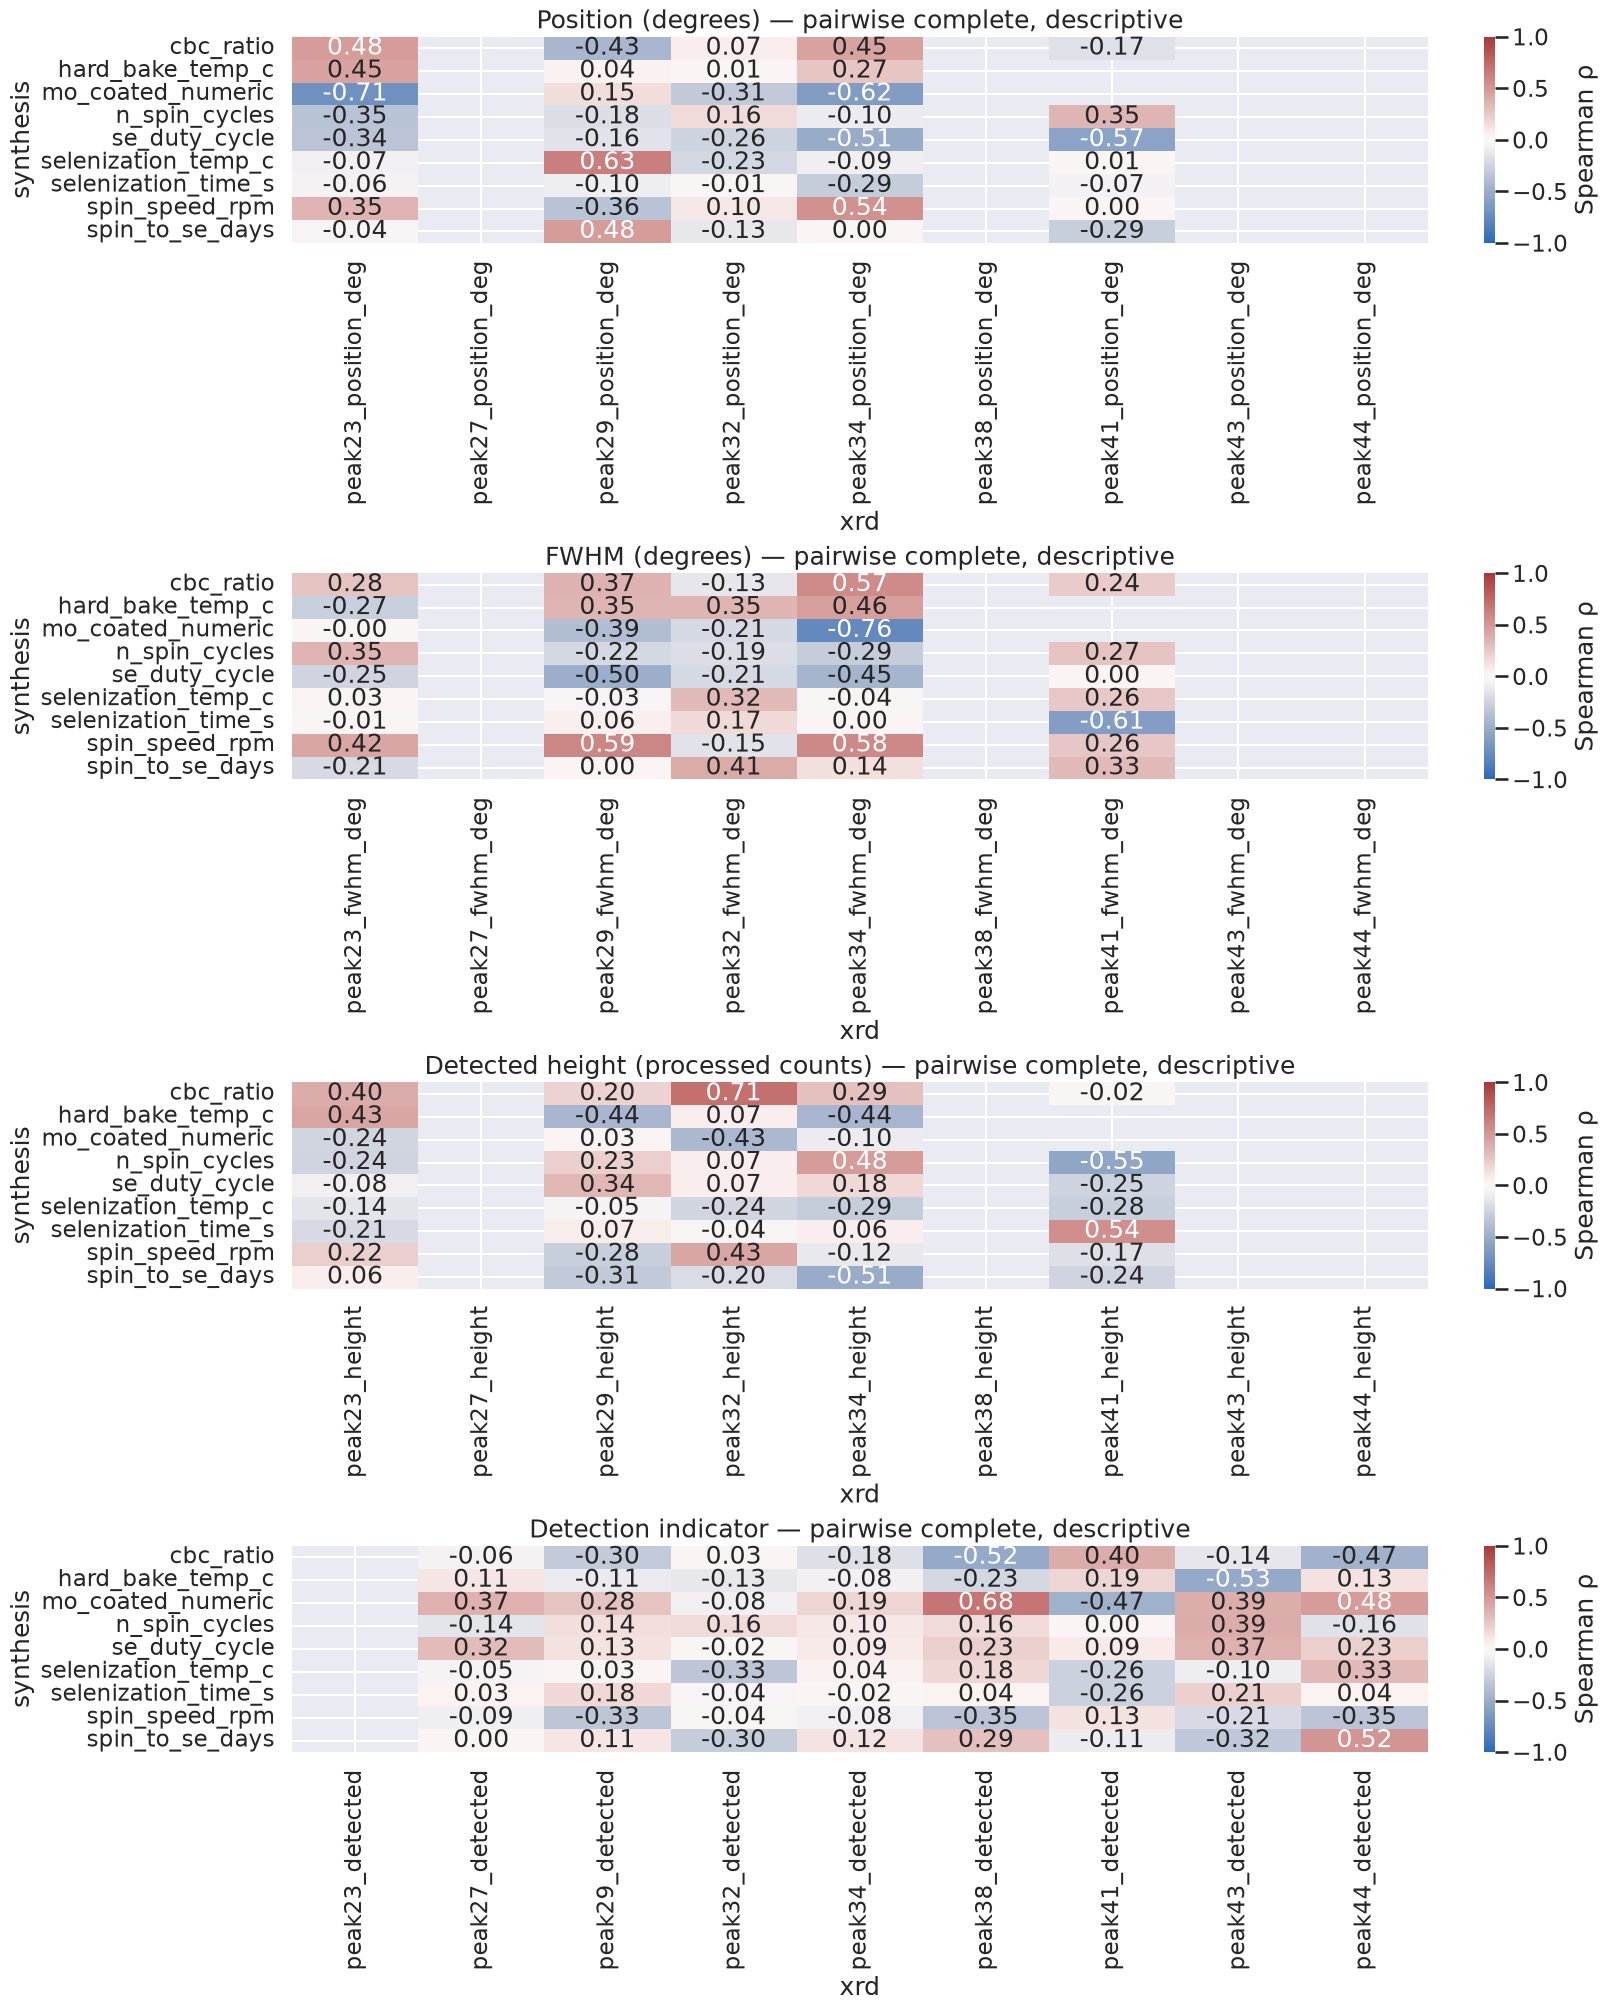

,synthesis,xrd,method,n,correlation,p_value,q_bh,abs_rho
602,mo_coated_numeric,peak34_fwhm_deg,spearman,26,-0.760,0.000,0.001,0.760
238,cbc_ratio,peak32_height,spearman,23,0.709,0.000,0.008,0.709
576,mo_coated_numeric,peak23_position_deg,spearman,28,-0.709,0.000,0.002,0.709
640,mo_coated_numeric,peak38_detected,spearman,28,0.677,0.000,0.005,0.677
84,selenization_temp_c,peak29_position_deg,spearman,22,0.630,0.002,0.056,0.630
600,mo_coated_numeric,peak34_position_deg,spearman,26,-0.623,0.001,0.027,0.623
182,selenization_time_s,peak41_fwhm_deg,spearman,9,-0.615,0.078,0.331,0.615
446,spin_speed_rpm,peak29_fwhm_deg,spearman,24,0.589,0.002,0.056,0.589
458,spin_speed_rpm,peak34_fwhm_deg,spearman,26,0.577,0.002,0.056,0.577
324,se_duty_cycle,peak41_position_deg,spearman,8,-0.574,0.137,0.429,0.574


Exploratory BH q < 0.05: 5 of 201 Spearman tests


In [20]:
from scipy.stats import false_discovery_control

correlation_outputs = outputs + [f'{name}_detected' for name in regions]
rows = []
for x in inputs:
    for y in correlation_outputs:
        pair_data = merged[[x, y]].dropna()
        for method, func in [('spearman', spearmanr), ('pearson', pearsonr)]:
            rho, p = np.nan, np.nan
            if len(pair_data) >= 8 and pair_data[x].nunique() > 1 and pair_data[y].nunique() > 1:
                res = func(pair_data[x], pair_data[y])
                rho, p = float(res.statistic), float(res.pvalue)
            rows.append({'synthesis': x, 'xrd': y, 'method': method,
                         'n': len(pair_data), 'correlation': rho, 'p_value': p})
correlations = pd.DataFrame(rows)
correlations['q_bh'] = np.nan
for method in ('spearman', 'pearson'):
    mask = correlations['method'].eq(method) & correlations['p_value'].notna()
    correlations.loc[mask, 'q_bh'] = false_discovery_control(correlations.loc[mask, 'p_value'].to_numpy(), method='bh')
correlations.to_csv(OUT / 'peak_synthesis_correlations.csv', index=False)
spearman = correlations.query("method == 'spearman'")
fig, axes = plt.subplots(4, 1, figsize=(16, 20), layout='constrained')
for ax, suffix, title in zip(axes, ['position_deg', 'fwhm_deg', 'height', 'detected'],
                             ['Position (degrees)', 'FWHM (degrees)', 'Detected height (processed counts)', 'Detection indicator']):
    panel = spearman[spearman.xrd.str.endswith('_' + suffix)].pivot(index='synthesis', columns='xrd', values='correlation')
    sns.heatmap(panel, cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', ax=ax,
                cbar_kws={'label': 'Spearman ρ'})
    ax.set_title(title + ' — pairwise complete, descriptive')
fig.savefig(OUT / 'peak_synthesis_spearman_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()
display(spearman.dropna(subset=['correlation']).assign(abs_rho=lambda d: d.correlation.abs())
        .sort_values('abs_rho', ascending=False).head(12).round(3))
print('Exploratory BH q < 0.05:', int((spearman.q_bh < 0.05).sum()), 'of', spearman.p_value.notna().sum(), 'Spearman tests')

### Peak coverage and a direct example

The detection map shows which film contributes to each region; a missing detection is not a zero-intensity observation. Below, the 32° height versus CBC example is colored by series. Near 32° the peak list includes both target and impurity labels, so it is a mixed-candidate region rather than a unique phase reflection.

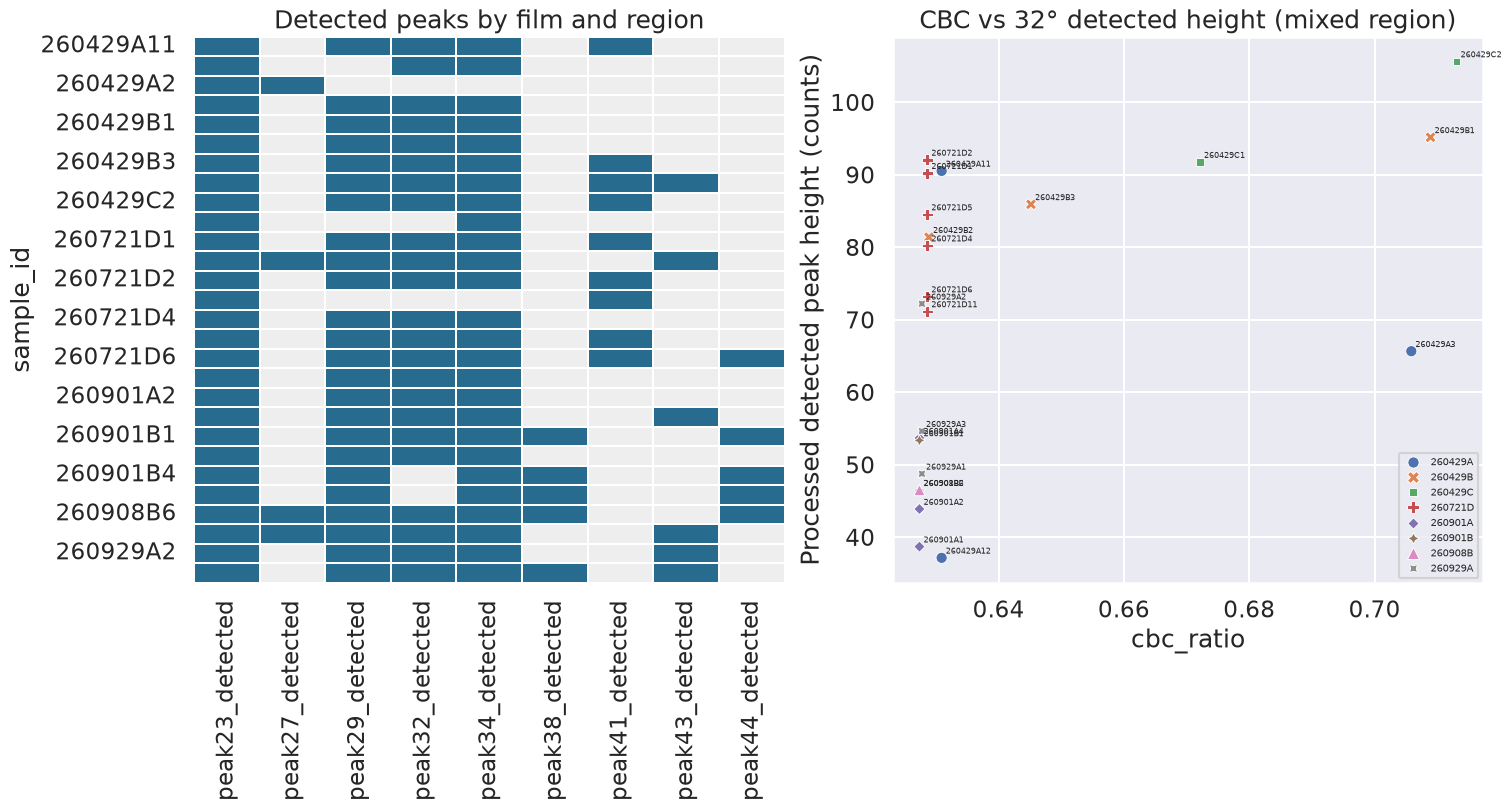

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), layout='constrained')
detection = merged.set_index('sample_id')[[f'{name}_detected' for name in regions]]
sns.heatmap(detection, cmap=sns.color_palette(['#eeeeee', '#276b8f']), vmin=0, vmax=1,
            cbar=False, linewidths=0.3, ax=axes[0])
axes[0].set_title('Detected peaks by film and region')
example = merged.dropna(subset=['cbc_ratio', 'peak32_height'])
sns.scatterplot(data=example, x='cbc_ratio', y='peak32_height', hue='series', style='series', s=65, ax=axes[1])
for _, row in example.iterrows():
    axes[1].annotate(row.sample_id, (row.cbc_ratio, row.peak32_height), fontsize=6,
                     xytext=(3, 3), textcoords='offset points')
axes[1].set_title('CBC vs 32° detected height (mixed region)')
axes[1].set_ylabel('Processed detected peak height (counts)')
axes[1].legend(fontsize=7)
fig.savefig(OUT / 'peak_detection_and_cbc_example.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. PCA: detected-peak features and combined features

Each block is standardized separately after median imputation. Only regions detected in at least 75% of films contribute position, width and height; indicators are not imputed as physical measurements. Principal components summarize variation in the chosen descriptors, not variance explained in the original diffraction patterns. The combined PCA includes both synthesis and XRD features, so it cannot independently demonstrate that synthesis predicts XRD. Feature loadings depend on the chosen regions, outliers and imputation; detected heights can reflect measurement conditions.

xrd_only explained variance PC1, PC2: [0.287 0.184]


,PC1,PC2,abs_PC1
peak29_fwhm_deg,0.431,0.008,0.431
peak34_fwhm_deg,0.387,-0.084,0.387
peak34_position_deg,0.382,0.040,0.382
peak29_height,-0.337,0.459,0.337
peak23_position_deg,0.319,-0.099,0.319
peak32_height,0.295,0.418,0.295


combined explained variance PC1, PC2: [0.274 0.168]


,PC1,PC2,abs_PC1
peak34_fwhm_deg,0.334,-0.057,0.334
mo_coated_numeric,-0.299,0.106,0.299
hard_bake_temp_c,0.292,0.256,0.292
peak23_position_deg,0.289,0.033,0.289
spin_speed_rpm,0.287,-0.227,0.287
peak29_height,-0.275,-0.229,0.275


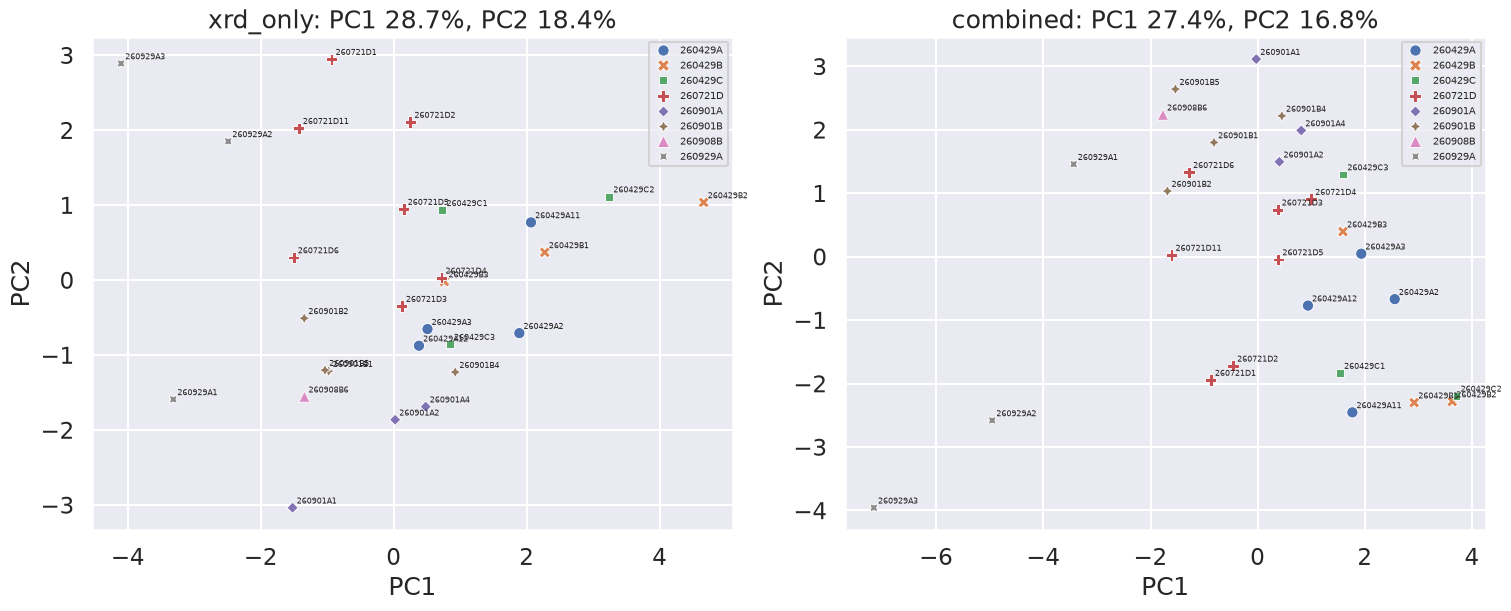

In [22]:
pca_models = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout='constrained')
for ax, name, X, features in zip(axes, ['xrd_only', 'combined'], [X_xrd, X_combined], [xrd_features, combined_features]):
    pca = PCA(n_components=2).fit(X)
    scores = pca.transform(X)
    pca_models[name] = pca
    score_table = pd.DataFrame({'sample_id': merged.sample_id, 'series': merged.series,
                                'PC1': scores[:, 0], 'PC2': scores[:, 1]})
    loadings = pd.DataFrame(pca.components_.T, index=features, columns=['PC1', 'PC2'])
    score_table.to_csv(OUT / f'pca_{name}_scores.csv', index=False)
    loadings.to_csv(OUT / f'pca_{name}_loadings.csv')
    sns.scatterplot(data=score_table, x='PC1', y='PC2', hue='series', style='series', s=65, ax=ax)
    for _, row in score_table.iterrows():
        ax.annotate(row['sample_id'], (row.PC1, row.PC2), fontsize=6, xytext=(3, 3), textcoords='offset points')
    ax.set_title(f'{name}: PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}')
    ax.legend(fontsize=7, loc='best')
    print(name, 'explained variance PC1, PC2:', np.round(pca.explained_variance_ratio_, 3))
    display(loadings.assign(abs_PC1=lambda d: d.PC1.abs()).sort_values('abs_PC1', ascending=False).head(6).round(3))
fig.savefig(OUT / 'pca_scores.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. XRD-only clustering and recipe comparison

Cluster the full standardized XRD feature space, **not** recipe plus outcome together; compare clusters with process metadata only after clustering. Ward hierarchical distances and K-means silhouettes for $k=2,3,4$ are exploratory: the highest silhouette is not proof of distinct physical phases. Median imputation, correlated descriptors, outliers, and series effects can dominate the result.

Chosen k by silhouette: 3 ; Ward vs K-means ARI: 0.761


,k,silhouette,inertia
0,2,0.147,273.001
1,3,0.151,228.848
2,4,0.142,202.749


Cluster counts and recipe medians (descriptive):


,hard_bake_temp_c,selenization_temp_c,selenization_time_s,cbc_ratio,se_duty_cycle,n_spin_cycles,spin_speed_rpm,spin_to_se_days,mo_coated_numeric
xrd_kmeans_cluster,,,,,,,,,
1,250.0,540.0,1200.0,0.645,0.156,1.0,2000.0,0.97,0.0
2,250.0,540.0,1200.0,0.627,0.156,1.0,1500.0,0.97,1.0
3,250.0,540.0,1200.0,0.629,0.312,1.0,1500.0,0.89,0.5


xrd_kmeans_cluster,1,2,3
series,,,
260429A,3,1,0
260429B,3,0,0
260429C,2,1,0
260721D,2,1,4
260901A,1,2,0
260901B,0,4,0
260908B,0,1,0
260929A,0,1,2


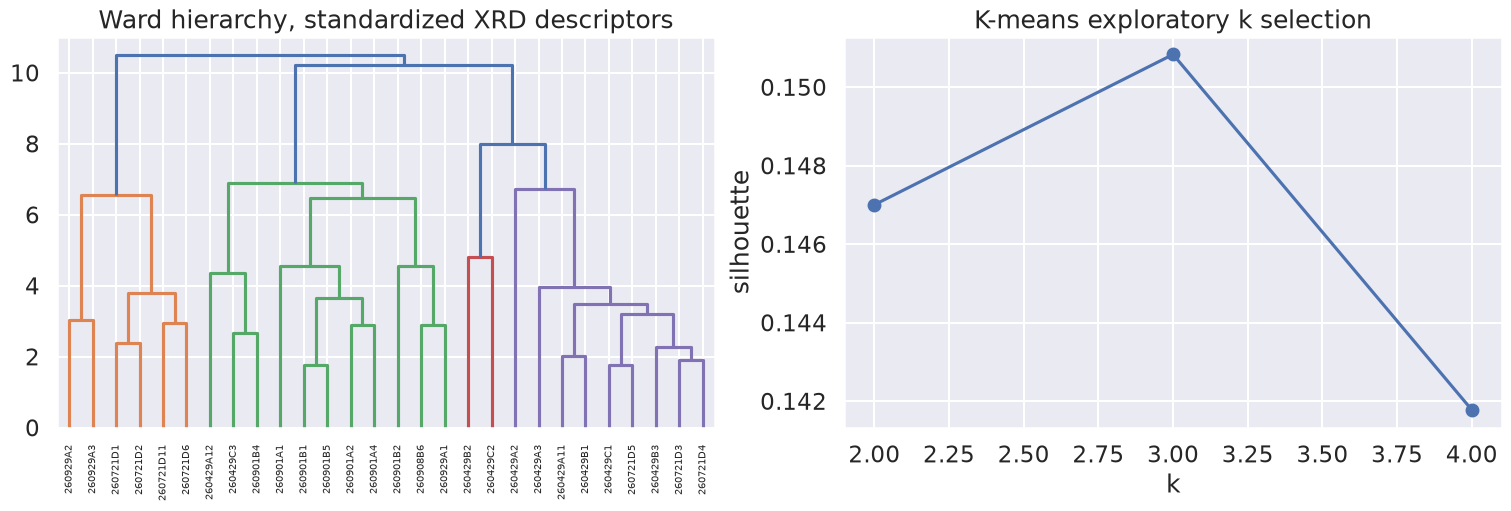

In [23]:
cluster_trials = []
for k in range(2, min(5, len(merged))):
    fit = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_xrd)
    cluster_trials.append({'k': k, 'silhouette': silhouette_score(X_xrd, fit.labels_), 'inertia': fit.inertia_})
cluster_trials = pd.DataFrame(cluster_trials)
chosen_k = int(cluster_trials.loc[cluster_trials.silhouette.idxmax(), 'k'])
km = KMeans(n_clusters=chosen_k, n_init=20, random_state=SEED).fit(X_xrd)
ward = linkage(X_xrd, method='ward')
merged['xrd_kmeans_cluster'] = km.labels_ + 1
merged['xrd_ward_cluster'] = fcluster(ward, chosen_k, criterion='maxclust')
print('Chosen k by silhouette:', chosen_k, '; Ward vs K-means ARI:', round(adjusted_rand_score(km.labels_, merged.xrd_ward_cluster), 3))
display(cluster_trials.round(3))
print('Cluster counts and recipe medians (descriptive):')
display(merged.groupby('xrd_kmeans_cluster')[inputs].median().round(3))
display(pd.crosstab(merged['series'], merged['xrd_kmeans_cluster']))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout='constrained')
dendrogram(ward, labels=merged.sample_id.to_list(), leaf_rotation=90, leaf_font_size=7, ax=axes[0])
axes[0].set_title('Ward hierarchy, standardized XRD descriptors')
axes[1].plot(cluster_trials.k, cluster_trials.silhouette, 'o-', label='silhouette')
axes[1].set(xlabel='k', ylabel='silhouette', title='K-means exploratory k selection')
fig.savefig(OUT / 'xrd_clustering.png', dpi=180, bbox_inches='tight')
plt.show()
merged[['sample_id', 'series', 'xrd_kmeans_cluster', 'xrd_ward_cluster', *inputs]].to_csv(OUT / 'xrd_cluster_assignments.csv', index=False)
cluster_trials.to_csv(OUT / 'cluster_selection.csv', index=False)

## 8–9. Stability, confounding checks and exports

For sensitivity, repeatedly select 80% of films **without replacement**, refit imputation, scaling, PCA and K-means, then compare PC1 loadings by absolute cosine (sign is arbitrary) and cluster labels by adjusted Rand index on the shared films. These are exploratory stability summaries, not confidence intervals and not independent-series resampling. For the strongest pooled Spearman pair, an ordinary film bootstrap gives a descriptive interval; dependence within series and selection of the strongest pair make it overly optimistic. The series-by-Mo table exposes a key possible confounder. Exports are written only under the dedicated exploration output folder.

XRD PCA PC1 absolute loading cosine, subsample vs full: {0.1: 0.903, 0.5: 0.979, 0.9: 0.995}
K-means ARI when both full-data clusters are present: {0.1: 0.132, 0.5: 0.584, 0.9: 1.0}
Subsamples with only one full-data cluster: 0 of 100
Full-data cluster sizes: {1: 11, 2: 11, 3: 6}
Strongest pooled pair: mo_coated_numeric vs peak34_fwhm_deg, n=26, ρ=-0.760, BH q=0.00134
Descriptive naive-film bootstrap 95% interval: [-0.866 -0.559]
Mo coating by series (possible confounding):


mo_coated_numeric,0.0,1.0
series,,
260429A,4,0
260429B,3,0
260429C,3,0
260721D,6,1
260901A,3,0
260901B,0,4
260908B,0,1
260929A,0,3


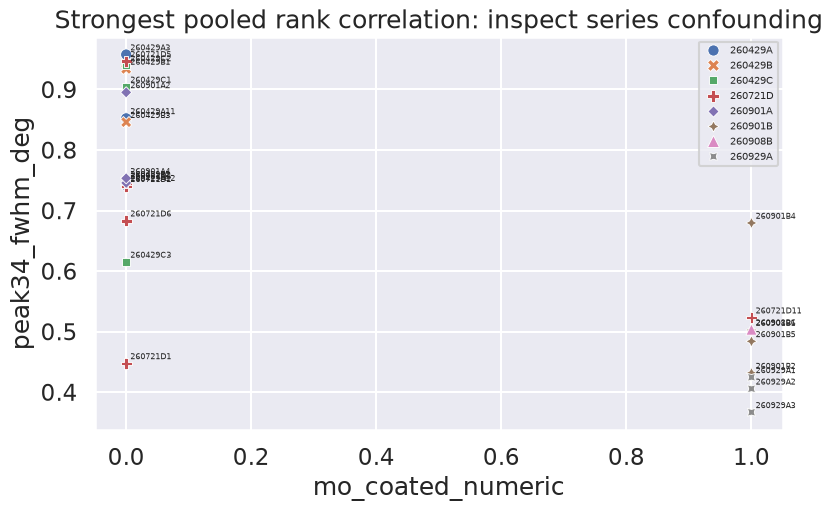

Outputs saved to /home/nomad-lanasc/xrd-bo-optimization-tf/outputs/synthesis_xrd_peak_exploration


In [24]:
rng = np.random.default_rng(SEED)
stability = []
for replicate in range(100):
    idx = np.sort(rng.choice(len(merged), size=max(chosen_k + 2, int(0.8 * len(merged))), replace=False))
    subset = merged.iloc[idx][xrd_features]
    local = make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), StandardScaler())
    X_sub = local.fit_transform(subset)
    pca_sub = PCA(n_components=2).fit(X_sub)
    cosine = abs(float(np.dot(pca_models['xrd_only'].components_[0], pca_sub.components_[0])))
    labels_sub = KMeans(n_clusters=chosen_k, n_init=10, random_state=SEED).fit_predict(X_sub)
    baseline = km.labels_[idx]
    ari = adjusted_rand_score(baseline, labels_sub) if len(np.unique(baseline)) > 1 else np.nan
    stability.append({'replicate': replicate, 'pc1_loading_abs_cosine': cosine, 'cluster_ari': ari,
                      'baseline_clusters_present': len(np.unique(baseline))})
stability = pd.DataFrame(stability)
stability.to_csv(OUT / 'subsample_stability.csv', index=False)
print('XRD PCA PC1 absolute loading cosine, subsample vs full:', stability.pc1_loading_abs_cosine.quantile([.1, .5, .9]).round(3).to_dict())
print('K-means ARI when both full-data clusters are present:', stability.cluster_ari.quantile([.1, .5, .9]).round(3).to_dict())
print('Subsamples with only one full-data cluster:', stability.cluster_ari.isna().sum(), 'of', len(stability))
print('Full-data cluster sizes:', merged.xrd_kmeans_cluster.value_counts().to_dict())

strongest = spearman.dropna(subset=['correlation']).assign(abs_rho=lambda d: d.correlation.abs()).sort_values('abs_rho', ascending=False).iloc[0]
x, y = strongest['synthesis'], strongest['xrd']
pair = merged[['sample_id', 'series', x, y]].dropna()
boot = []
for _ in range(1000):
    sample = pair.iloc[rng.integers(len(pair), size=len(pair))]
    if sample[x].nunique() > 1 and sample[y].nunique() > 1:
        boot.append(spearmanr(sample[x], sample[y]).statistic)
print(f'Strongest pooled pair: {x} vs {y}, n={len(pair)}, ρ={strongest.correlation:.3f}, BH q={strongest.q_bh:.3g}')
print('Descriptive naive-film bootstrap 95% interval:', np.round(np.quantile(boot, [.025, .975]), 3))
print('Mo coating by series (possible confounding):')
display(pd.crosstab(merged.series, merged.mo_coated_numeric, dropna=False))
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
sns.scatterplot(data=pair, x=x, y=y, hue='series', style='series', s=65, ax=ax)
for _, row in pair.iterrows():
    ax.annotate(row['sample_id'], (row[x], row[y]), fontsize=6, xytext=(3, 3), textcoords='offset points')
ax.set_title('Strongest pooled rank correlation: inspect series confounding')
ax.legend(fontsize=7, bbox_to_anchor=(1, 1))
fig.savefig(OUT / 'strongest_pooled_association.png', dpi=180, bbox_inches='tight')
plt.show()
print(f'Outputs saved to {OUT}')

### Peak-region and series sensitivity

Remove the region associated with the strongest pooled correlation from XRD clustering and recompute the correlation after leaving each series out. This explores sensitivity to a selected feature and series; it does not establish a causal or phase assignment.

In [25]:
region = y.split('_')[0]
selected_features = [c for c in xrd_features if not c.startswith(region + '_')]
if len(selected_features) >= 2:
    reduced_features, X_reduced, _ = make_matrix(selected_features)
    km_reduced = KMeans(n_clusters=chosen_k, n_init=20, random_state=SEED).fit(X_reduced)
    print('Without region', region, ': cluster sizes', pd.Series(km_reduced.labels_).value_counts().to_dict(),
          '; ARI versus full-feature clustering', round(adjusted_rand_score(km.labels_, km_reduced.labels_), 3))
else:
    print('Insufficient features remain for region-removal sensitivity')
leave_series = []
for series in sorted(pair.series.unique()):
    sub = pair[pair.series != series]
    rho = spearmanr(sub[x], sub[y]).statistic if sub[x].nunique() > 1 and sub[y].nunique() > 1 else np.nan
    leave_series.append({'left_out_series': series, 'n': len(sub), 'spearman_rho': rho})
leave_series = pd.DataFrame(leave_series)
leave_series.to_csv(OUT / 'peak_association_leave_series_out.csv', index=False)
display(leave_series.round(3))

Without region peak34 : cluster sizes {1: 14, 2: 12, 0: 2} ; ARI versus full-feature clustering 0.098


,left_out_series,n,spearman_rho
0,260429A,23,-0.766
1,260429B,23,-0.766
2,260429C,23,-0.779
3,260721D,20,-0.832
4,260901A,23,-0.766
5,260901B,22,-0.692
6,260908B,25,-0.749
7,260929A,23,-0.672


## Interpretation checklist

- Inspect the strongest associations and their sample counts alongside the series/coating cross-tab; pooled correlation cannot disentangle coating from series or other synthesis changes.
- If a cluster is a singleton, treat it as a potential outlier or processing/measurement issue, not a phase class. Compare its original pattern and feature values before drawing conclusions.
- Use the correlations and PCA loadings to select **hypotheses** for controlled follow-up experiments, not recipes or physical phase fractions. Repeat measurements and matched comparisons across substrate and series are particularly valuable.
- Figures and CSVs in the dedicated output folder can be regenerated by running this notebook top to bottom; no source files or BO outputs are overwritten.